<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1 & 2: Dataset Generation and Network Initialization
We will first generate the XOR-style dataset and a two-moons customer-segmentation dataset. Then, we will initialize weights for an input-hidden-output network structure using NumPy.

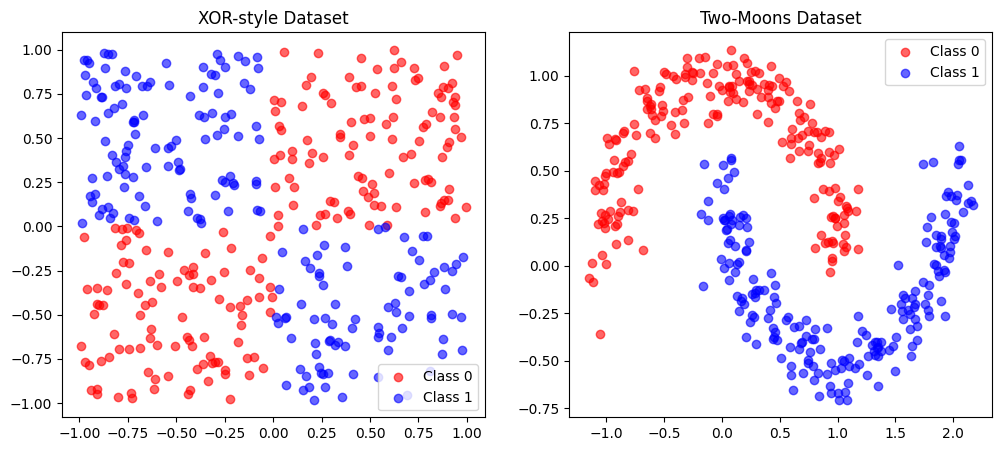

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate Datasets
# Dataset A: XOR-style dataset
X_xor = np.random.uniform(-1, 1, (400, 2))
y_xor = ( (X_xor[:, 0] > 0) ^ (X_xor[:, 1] > 0) ).astype(int).reshape(-1, 1)

# Dataset B: Two-Moons dataset
# In scikit-learn, the parameter name is 'random_state'
X_moons, y_moons = make_moons(n_samples=400, noise=0.1, random_state=42)
y_moons = y_moons.reshape(-1, 1)

# Plotting the datasets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(X_xor[y_xor.flatten() == 0, 0], X_xor[y_xor.flatten() == 0, 1], c='red', label='Class 0', alpha=0.6)
ax1.scatter(X_xor[y_xor.flatten() == 1, 0], X_xor[y_xor.flatten() == 1, 1], c='blue', label='Class 1', alpha=0.6)
ax1.set_title("XOR-style Dataset")
ax1.legend()

ax2.scatter(X_moons[y_moons.flatten() == 0, 0], X_moons[y_moons.flatten() == 0, 1], c='red', label='Class 0', alpha=0.6)
ax2.scatter(X_moons[y_moons.flatten() == 1, 0], X_moons[y_moons.flatten() == 1, 1], c='blue', label='Class 1', alpha=0.6)
ax2.set_title("Two-Moons Dataset")
ax2.legend()
plt.show()

### Task 2 & 3: Two-Layer Neural Network Class
Here, we define our custom neural network class from scratch. We implement the sigmoid activation, the forward pass, and the backward pass using the derived chain rule formulas.

In [2]:
class TwoLayerNN:
    def __init__(self, input_dim, hidden_dim, output_dim=1, lr=0.1):
        # Initialize weights and biases
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))
        self.lr = lr

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def sigmoid_derivative(self, a):
        # Derivative of sigmoid activation with respect to its input, given active output a
        return a * (1.0 - a)

    def forward(self, X):
        self.X = X
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def backward(self, y):
        m = y.shape[0]
        # Loss: Binary Cross Entropy
        # dL/da2
        da2 = - (y / self.a2) + ((1 - y) / (1 - self.a2))
        # dL/dz2 = (dL/da2) * (da2/dz2)
        dz2 = self.a2 - y # Simplified form for sigmoid + BCE loss

        self.dW2 = np.dot(self.a1.T, dz2) / m
        self.db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Propagate back to hidden layer
        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.sigmoid_derivative(self.a1)

        self.dW1 = np.dot(self.X.T, dz1) / m
        self.db1 = np.sum(dz1, axis=0, keepdims=True) / m

    def update(self):
        self.W1 -= self.lr * self.dW1
        self.b1 -= self.lr * self.db1
        self.W2 -= self.lr * self.dW2
        self.b2 -= self.lr * self.db2

    def compute_loss(self, y_pred, y):
        m = y.shape[0]
        eps = 1e-15
        y_pred = np.clip(y_pred, eps, 1.0 - eps)
        return -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))

### Task 5: Numerical Gradient Verification
Before we train the network, we verify our backward pass derivatives using finite-difference numerical approximation for a single weight parameter.

In [3]:
# Initialize small network to test gradients
_nn = TwoLayerNN(input_dim=2, hidden_dim=3, output_dim=1)
X_test, y_test = X_xor[:5], y_xor[:5] # Small test batch

# Analytical gradient calculation
a2 = _nn.forward(X_test)
_nn.backward(y_test)
analytical_grad = _nn.dW1[0, 0]

# Numerical gradient calculation
epsilon = 1e-5
_nn.W1[0, 0] += epsilon
loss_plus = _nn.compute_loss(_nn.forward(X_test), y_test)

_nn.W1[0, 0] -= 2 * epsilon
loss_minus = _nn.compute_loss(_nn.forward(X_test), y_test)

# Reset weight
_nn.W1[0, 0] += epsilon

numerical_grad = (loss_plus - loss_minus) / (2 * epsilon)
print(f"Analytical Gradient for W1[0,0]: {analytical_grad:.8f}")
print(f"Numerical Gradient for W1[0,0]:  {numerical_grad:.8f}")
print(f"Absolute Difference:            {abs(analytical_grad - numerical_grad):.2e}")

Analytical Gradient for W1[0,0]: -0.01624885
Numerical Gradient for W1[0,0]:  -0.01624885
Absolute Difference:            9.60e-12


### Task 4 & 5: Training and Decision Boundary Visualization
Now we train our networks on both the XOR and Two-Moons datasets, plotting loss histories and the resulting non-linear decision boundaries.

XOR Dataset | Epoch    0 | Loss: 0.7056
XOR Dataset | Epoch 1000 | Loss: 0.1785
XOR Dataset | Epoch 2000 | Loss: 0.1125
XOR Dataset | Epoch 3000 | Loss: 0.0919
XOR Dataset | Epoch 4000 | Loss: 0.0807


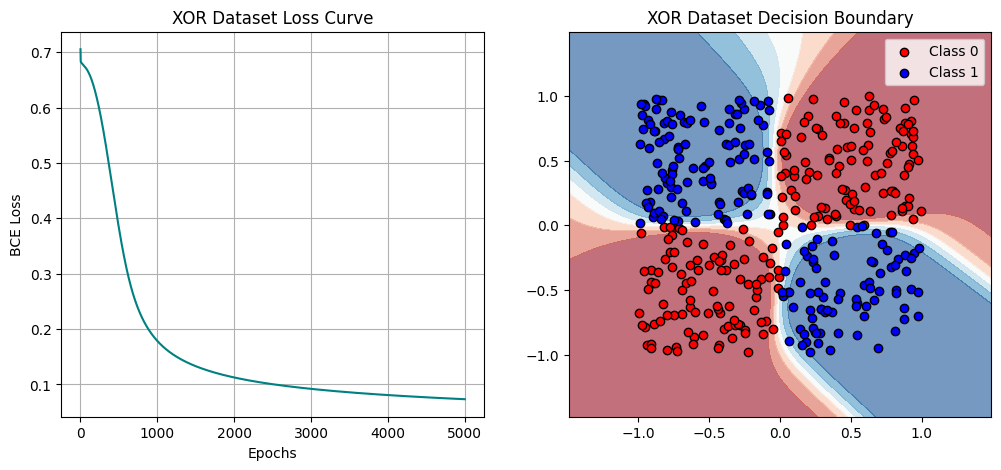

Two-Moons Dataset | Epoch    0 | Loss: 0.6581
Two-Moons Dataset | Epoch 1000 | Loss: 0.2674
Two-Moons Dataset | Epoch 2000 | Loss: 0.1515
Two-Moons Dataset | Epoch 3000 | Loss: 0.0513
Two-Moons Dataset | Epoch 4000 | Loss: 0.0261


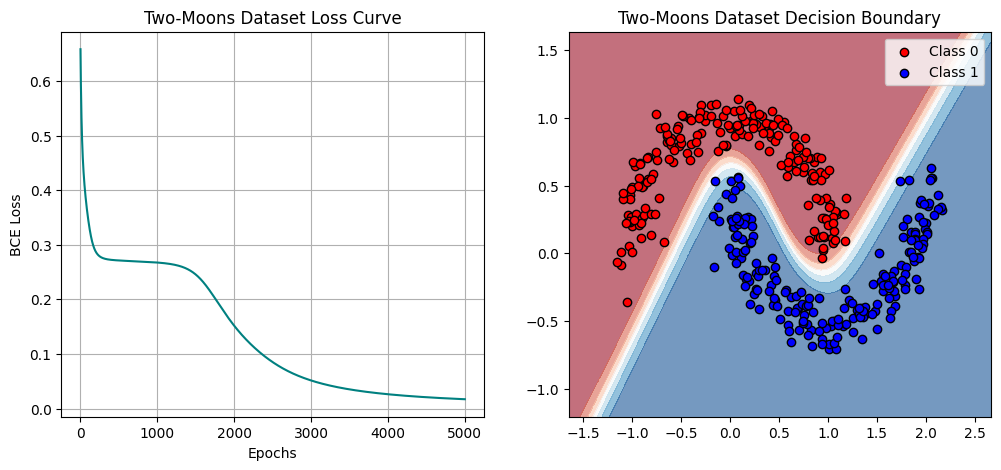

In [6]:
def train_and_evaluate(X, y, title, epochs=5000, lr=0.5, hidden_dim=8):
    nn = TwoLayerNN(input_dim=2, hidden_dim=hidden_dim, lr=lr)
    loss_history = []

    for epoch in range(epochs):
        y_pred = nn.forward(X)
        loss = nn.compute_loss(y_pred, y)
        loss_history.append(loss)

        nn.backward(y)
        nn.update()

        if epoch % (epochs // 5) == 0:
            print(f"{title} | Epoch {epoch:4d} | Loss: {loss:.4f}")

    # Plot results
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Loss history
    ax1.plot(loss_history, color='teal')
    ax1.set_title(f"{title} Loss Curve")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("BCE Loss")
    ax1.grid(True)

    # Decision Boundary
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    grid_preds = nn.forward(grid_points).reshape(xx.shape)

    ax2.contourf(xx, yy, grid_preds, cmap='RdBu', alpha=0.6)
    ax2.scatter(X[y.flatten() == 0, 0], X[y.flatten() == 0, 1], c='red', edgecolors='k', label='Class 0')
    ax2.scatter(X[y.flatten() == 1, 0], X[y.flatten() == 1, 1], c='blue', edgecolors='k', label='Class 1')
    ax2.set_title(f"{title} Decision Boundary")
    ax2.legend()
    plt.show()

train_and_evaluate(X_xor, y_xor, "XOR Dataset")
train_and_evaluate(X_moons, y_moons, "Two-Moons Dataset")